# Sentiment Intelligence — Data Exploration

## Notebook 01: Dataset Profiling and Quality Assessment

**Dataset:** UCI Sentiment Labelled Sentences

**Sources:** Amazon, IMDb, Yelp

**Objective:** Understand the corpus, validate its integrity, investigate duplicates,
study source-wise differences, and assess text-length and label distributions.

### Research principles
- Preserve the original text during initial exploration.
- Do not remove duplicates or records without investigating them.
- Keep the source domain available for cross-domain evaluation.
- Fit learned preprocessing only on training data in later experiments.
- Do not use the test set to make preprocessing or model-selection decisions.

**Label encoding:** `0 = Negative`, `1 = Positive`.


## 1. Imports and project configuration

In [1]:
from collections import Counter
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

RANDOM_STATE = 42

# Locate the project root even if the notebook kernel starts in another directory.
cwd = Path.cwd()
PROJECT_ROOT = next(
    (
        path for path in [cwd, *cwd.parents]
        if (
            path / "data/interim/sentiment/"
            "sentiment_labelled_sentences.csv"
        ).exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. "
        "Open this notebook from the project workspace."
    )

DATA_PATH = (
    PROJECT_ROOT / "data/interim/sentiment/"
    "sentiment_labelled_sentences.csv"
)
METADATA_PATH = (
    PROJECT_ROOT / "data/interim/sentiment/dataset_metadata.json"
)

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())


Project root: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent
Dataset: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/data/interim/sentiment/sentiment_labelled_sentences.csv
Dataset exists: True


## 2. Load the reconstructed dataset and metadata

In [2]:
df = pd.read_csv(DATA_PATH)

with METADATA_PATH.open(encoding="utf-8") as file:
    metadata = json.load(file)

required_columns = {"source", "text", "label"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["source"] = df["source"].astype("string")
df["text"] = df["text"].astype("string")
df["label"] = pd.to_numeric(df["label"], errors="raise").astype("int64")

print("Dataset shape:", df.shape)
print("\nMetadata:")
display(pd.Series(metadata))

print("\nFirst 10 records:")
display(df.head(10))


Dataset shape: (3000, 3)

Metadata:


dataset                                                                                                              UCI Sentiment Labelled Sentences
archive_sha256                                                                       afc26626d710899948693e1a61405dce197f57ffa719fa1130d346b4cc095343
sources                       {'amazon': {'filename': 'amazon_cells_labelled.txt', 'physical_lines': 1000, 'records': 1000, 'negative': 500, 'posi...
total_records                                                                                                                                    3000
parser                                                                                      Reconstruct records ending in tab-separated binary labels
overall_label_distribution                                                                                       {'negative': 1500, 'positive': 1500}
dtype: object


First 10 records:


,source,text,label
0,amazon,So there is no way for me to plug it in here in the US unless I go by a converter.,0
1,amazon,"Good case, Excellent value.",1
2,amazon,Great for the jawbone.,1
3,amazon,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0
4,amazon,The mic is great.,1
5,amazon,I have to jiggle the plug to get it to line up right to get decent volume.,0
6,amazon,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of them one by one.",0
7,amazon,If you are Razr owner...you must have this!,1
8,amazon,"Needless to say, I wasted my money.",0
9,amazon,What a waste of money and time!.,0


## 3. Dataset integrity checks

In [3]:
expected_sources = {"amazon", "imdb", "yelp"}

assert len(df) == 3000, f"Expected 3000 records, found {len(df)}"
assert set(df["source"].unique()) == expected_sources
assert set(df["label"].unique()) == {0, 1}
assert df["text"].notna().all(), "Null text values found"
assert df["source"].notna().all(), "Null source values found"

source_counts = df["source"].value_counts().sort_index()
label_counts = df["label"].value_counts().sort_index()

display(source_counts.rename("records").to_frame())
display(label_counts.rename(index={0: "negative", 1: "positive"}).to_frame())

source_label_counts = pd.crosstab(df["source"], df["label"])
source_label_counts.columns = ["negative", "positive"]

display(source_label_counts)

assert (source_counts == 1000).all()
assert (source_label_counts == 500).all().all()

print("All dataset integrity checks passed.")


,records
source,
amazon,1000
imdb,1000
yelp,1000


,count
label,
negative,1500
positive,1500


,negative,positive
source,,
amazon,500,500
imdb,500,500
yelp,500,500


All dataset integrity checks passed.


## 4. Missing values and text formatting

We inspect missing values, empty strings and surrounding whitespace.
We will not lowercase, stem, lemmatize or remove punctuation at this stage.


In [4]:
missing_report = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percentage": df.isna().mean().mul(100).round(3),
})

display(missing_report)

text_stripped = df["text"].str.strip()

print("Empty or whitespace-only sentences:", int(text_stripped.eq("").sum()))
print("Leading/trailing whitespace:", int(df["text"].ne(text_stripped).sum()))
print("Duplicate source values:", int(df["source"].isna().sum()))
print("Invalid labels:", int((~df["label"].isin([0, 1])).sum()))


,missing_values,missing_percentage
source,0,0.0
text,0,0.0
label,0,0.0


Empty or whitespace-only sentences: 0
Leading/trailing whitespace: 0
Duplicate source values: 0
Invalid labels: 0


## 5. Duplicate investigation

We distinguish:
- Exact duplicate sentences within a source.
- Exact sentence overlap across sources.
- Duplicates after case and whitespace normalisation.
- Identical normalised sentences that have conflicting labels.

These are diagnostics only. No rows are deleted.


In [5]:
analysis_df = df.copy()

analysis_df["normalised_key"] = (
    analysis_df["text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

within_source_duplicate_rows = analysis_df.duplicated(
    subset=["source", "text"], keep=False
)
global_duplicate_rows = analysis_df.duplicated(
    subset=["text"], keep=False
)
normalised_duplicate_rows = analysis_df.duplicated(
    subset=["normalised_key"], keep=False
)

normalised_groups = (
    analysis_df.groupby("normalised_key", dropna=False)
    .agg(
        occurrences=("text", "size"),
        source_count=("source", "nunique"),
        label_count=("label", "nunique"),
        sources=("source", lambda values: ", ".join(sorted(set(values)))),
        labels=("label", lambda values: sorted(set(values))),
    )
)

cross_source_groups = normalised_groups[
    normalised_groups["source_count"] > 1
]
conflicting_groups = normalised_groups[
    normalised_groups["label_count"] > 1
]

duplicate_summary = pd.Series({
    "rows_in_exact_within_source_duplicate_groups":
        int(within_source_duplicate_rows.sum()),
    "rows_in_exact_global_duplicate_groups":
        int(global_duplicate_rows.sum()),
    "rows_in_normalised_duplicate_groups":
        int(normalised_duplicate_rows.sum()),
    "normalised_groups_shared_across_sources":
        len(cross_source_groups),
    "normalised_groups_with_conflicting_labels":
        len(conflicting_groups),
})

display(duplicate_summary.to_frame("count"))

print("Examples of cross-source overlaps:")
display(cross_source_groups.head(15))

print("Examples of conflicting-label groups:")
display(conflicting_groups.head(15))


,count
rows_in_exact_within_source_duplicate_groups,34
rows_in_exact_global_duplicate_groups,36
rows_in_normalised_duplicate_groups,40
normalised_groups_shared_across_sources,1
normalised_groups_with_conflicting_labels,0


Examples of cross-source overlaps:


,occurrences,source_count,label_count,sources,labels
normalised_key,,,,,
very disappointing.,2,2,1,"amazon, imdb",[0]


Examples of conflicting-label groups:


,occurrences,source_count,label_count,sources,labels
normalised_key,,,,,


## 6. Class distribution

label,Negative,Positive
source,,
amazon,500,500
imdb,500,500
yelp,500,500


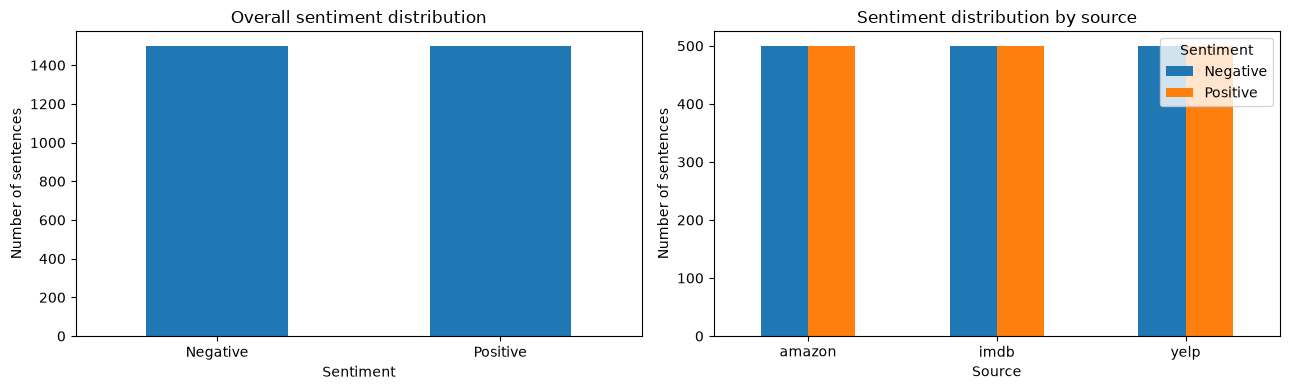

In [6]:
class_distribution = (
    df.groupby(["source", "label"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "Negative", 1: "Positive"})
)

display(class_distribution)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df["label"].map({0: "Negative", 1: "Positive"}).value_counts().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Overall sentiment distribution")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Number of sentences")
axes[0].tick_params(axis="x", rotation=0)

class_distribution.plot(kind="bar", ax=axes[1])
axes[1].set_title("Sentiment distribution by source")
axes[1].set_xlabel("Source")
axes[1].set_ylabel("Number of sentences")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Sentiment")

plt.tight_layout()
plt.show()


## 7. Sentence length analysis

In [7]:
# These are exploratory measurements, not preprocessing transformations.
df["character_count"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()

length_summary = (
    df.groupby(["source", "label"])
    .agg(
        records=("text", "size"),
        mean_words=("word_count", "mean"),
        median_words=("word_count", "median"),
        std_words=("word_count", "std"),
        min_words=("word_count", "min"),
        max_words=("word_count", "max"),
        mean_characters=("character_count", "mean"),
        median_characters=("character_count", "median"),
    )
    .round(2)
)

display(length_summary)
display(df[["word_count", "character_count"]].describe().round(2))


records  mean_words  median_words  std_words  min_words  max_words  mean_characters  median_characters
source label                                                                                                        
amazon 0          500       10.58          10.0       6.58          1         30            56.82               52.0
       1          500        9.91           8.0       6.79          1         30            53.63               43.0
imdb   0          500       13.58          11.0       9.04          1         56            75.09               63.0
       1          500       15.13          13.0      10.10          1         71            85.45               70.0
yelp   0          500       11.50          10.0       6.61          2         32            60.75               52.5
       1          500       10.29           9.0       5.83          1         32            55.88               49.5

,word_count,character_count
count,3000.00,3000.0
mean,11.83,64.6
std,7.87,43.92
min,1.00,5.0
25%,6.00,32.0
50%,10.00,55.0
75%,16.00,87.0
max,71.00,477.0


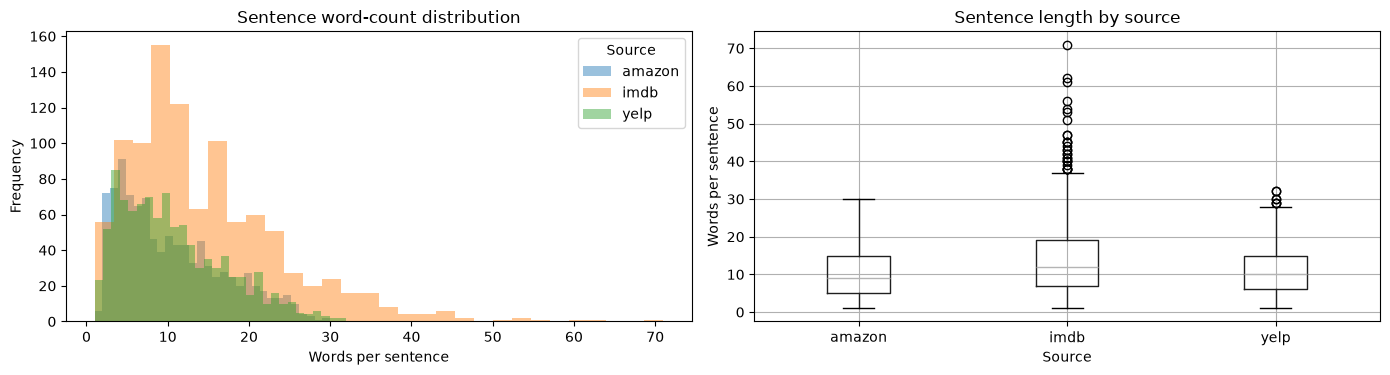

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for source, group in df.groupby("source"):
    axes[0].hist(
        group["word_count"],
        bins=30,
        alpha=0.45,
        label=source,
    )

axes[0].set_title("Sentence word-count distribution")
axes[0].set_xlabel("Words per sentence")
axes[0].set_ylabel("Frequency")
axes[0].legend(title="Source")

df.boxplot(
    column="word_count",
    by="source",
    ax=axes[1],
)
axes[1].set_title("Sentence length by source")
axes[1].set_xlabel("Source")
axes[1].set_ylabel("Words per sentence")

fig.suptitle("")
plt.tight_layout()
plt.show()


## 8. Sentence length by sentiment

median_words  mean_words  median_characters  mean_characters
source label                                                              
amazon 0              10.0       10.58               52.0            56.82
       1               8.0        9.91               43.0            53.63
imdb   0              11.0       13.58               63.0            75.09
       1              13.0       15.13               70.0            85.45
yelp   0              10.0       11.50               52.5            60.75
       1               9.0       10.29               49.5            55.88

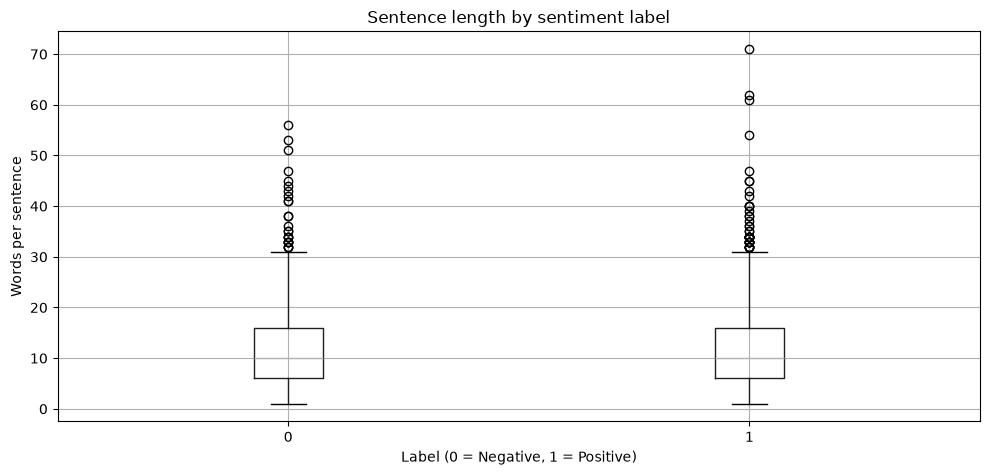

In [9]:
sentiment_length = (
    df.groupby(["source", "label"])
    .agg(
        median_words=("word_count", "median"),
        mean_words=("word_count", "mean"),
        median_characters=("character_count", "median"),
        mean_characters=("character_count", "mean"),
    )
    .round(2)
)

display(sentiment_length)

fig, ax = plt.subplots(figsize=(10, 5))
df.boxplot(
    column="word_count",
    by="label",
    ax=ax,
)
ax.set_title("Sentence length by sentiment label")
ax.set_xlabel("Label (0 = Negative, 1 = Positive)")
ax.set_ylabel("Words per sentence")
fig.suptitle("")
plt.tight_layout()
plt.show()

## 9. Exploratory vocabulary inspection

This is a simple token-frequency diagnostic using a regular expression.
It is not the final tokenizer and does not modify the original sentences.


In [ ]:
def exploratory_tokens(text):
    return re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", text.lower())

for source, group in df.groupby("source"):
    tokens = Counter(
        token
        for sentence in group["text"]
        for token in exploratory_tokens(sentence)
    )

    print(f"\n{source.upper()} — 20 most common tokens")
    display(pd.DataFrame(tokens.most_common(20), columns=["token", "frequency"]))


## 10. Inspect representative examples

In [ ]:
sample_examples = (
    df.groupby(["source", "label"], group_keys=False)
    .sample(n=5, random_state=RANDOM_STATE)
    .sort_values(["source", "label"])
    .copy()
)

sample_examples["sentiment"] = sample_examples["label"].map({
    0: "Negative",
    1: "Positive",
})

display(sample_examples[["source", "sentiment", "text"]])


## 11. Initial research observations

### Questions to answer
1. Are there duplicate or overlapping sentences across Amazon, IMDb and Yelp?
2. Do any identical sentences have conflicting labels?
3. Do the three sources have materially different sentence-length distributions?
4. Are positive and negative sentences noticeably different in length?
5. Are there unusually short, long or malformed sentences?
6. What preprocessing decisions should be tested rather than assumed?

### Decisions deliberately deferred
- Stopword removal
- Stemming and lemmatisation
- Lowercasing
- Punctuation removal
- Contraction handling
- Vocabulary truncation and sequence length
- Duplicate removal

These choices will be evaluated as part of the modelling experiments.


In [ ]:
print("FINAL NOTEBOOK DATA CHECK")
print("==========================")
print("Rows:", len(df))
print("Sources:", sorted(df["source"].unique().tolist()))
print("Label counts:", df["label"].value_counts().sort_index().to_dict())
print("Missing text:", int(df["text"].isna().sum()))
print("Empty text:", int(df["text"].str.strip().eq("").sum()))
print("Exact duplicate rows:", int(global_duplicate_rows.sum()))
print("Cross-source overlap groups:", len(cross_source_groups))
print("Conflicting-label groups:", len(conflicting_groups))

print("\nNo records were deleted or overwritten during this notebook.")
